## QM640 Capstone — Medicare Provider Data Quality & Exploratory Data Analysis

**Project:** Predicting Medicare Payment Costs and Identifying High-Cost Provider Patterns Using Machine Learning  
**Course:** QM640 — Data Analytics Capstone | **Mentor:** Sharath Srivatsa | **Term:** Fall 2026

This notebook adapts the supplied exploratory-data-analysis workflow to the **2024 CMS Medicare Physician & Other Practitioners — by Provider** dataset. It examines data structure, provider identifiers, missingness/suppression, payment distributions, category differences, potential leakage, cross-field consistency, and extreme values.

### Previously observed baseline results

The prior analysis of the project CSV reported **1,296,739 provider-level rows and 76 columns**. `Rndrng_NPI` was reported unique, with no exact duplicate rows or duplicate NPIs. The target `Tot_Mdcr_Pymt_Amt` was reported to have a mean of `$92,584.47`, median of `$26,513`, and a strongly right-skewed distribution. Eight records were reported with zero payment. Candidate high-cost cutoffs were the 90th percentile (`$151,995.92`), 95th percentile (`$261,353.12`), and 99th percentile (`$1,141,640.46`).

**Verification note:** These are previously observed baseline results, not outputs generated by this notebook run. The cells below recalculate the statistics from the CSV you select. If the file version differs, use the newly generated outputs as authoritative and update any written report accordingly.

**Important boundaries:** The unit of analysis is a provider/NPI aggregate, not a patient or claim. The data describe the CMS reporting scope, not all provider revenue or all healthcare coverage. High payment is not evidence of fraud, waste, abuse, or poor quality. Do not replace suppressed/missing values with zero, and do not automatically cap or delete high-payment records.


## 1. Context, research alignment, and project boundaries

This EDA prepares the dataset for the capstone research questions:

- **RQ1 — Group differences:** What provider, utilization, and beneficiary characteristics are associated with differences in Medicare payment costs?
- **RQ2 — Payment prediction:** Which eligible provider, utilization, and beneficiary characteristics predict payment amounts?
- **RQ3 — High-cost classification:** Which model most accurately identifies providers in a pre-defined high-cost group?
- **RQ4 — Risk scoring:** Can a provider-level score prioritize records for payment/utilization review?

The notebook does not answer these questions inferentially by itself. It creates data-quality evidence and descriptive outputs that inform later hypothesis tests and predictive modeling.

**Target planned for modeling:** `Tot_Mdcr_Pymt_Amt`.

**Potential leakage/timing concern:** Payment-related fields such as `Tot_Mdcr_Alowd_Amt` and `Tot_Mdcr_Stdzd_Amt`, and potentially submitted charges or service counts, must be reviewed against the intended prediction time. Do not use variables that directly encode the outcome or would not be available when the prediction is supposed to be made.

**Official source resources**
- CMS dataset: https://data.cms.gov/provider-summary-by-type-of-service/medicare-physician-other-practitioners/medicare-physician-other-practitioners-by-provider
- CMS API documentation: https://data.cms.gov/provider-summary-by-type-of-service/medicare-physician-other-practitioners/medicare-physician-other-practitioners-by-provider/api-docs
- CMS data dictionary: https://data.cms.gov/resources/medicare-physician-other-practitioners-by-provider-data-dictionary


## 2. Import libraries and set options

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### List the extracted files:

In [2]:
import os

for root, dirs, filenames in os.walk("/content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project"):
    for filename in filenames:
        print(os.path.join(root, filename))

/content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project/eda_medicare_provider_2024.py
/content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project/CMS_2024_EDA_Findings_and_Boundaries.md
/content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project/requirements.txt
/content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project/02_modeling_scaffold.py
/content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project/README_CMS_EDA.txt
/content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project/03_build_interim_report.py
/content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project/Interim_Report_Draft.pdf
/content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project/README.md
/content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project/cms_provider_2024.csv
/content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project/QM640_Healthcare_CMS_Capstone_Interim_Draft.docx
/content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project/QM640_Healthcare_CMS_Capstone_Interim_Draft.

### Install the required Python libraries

In [3]:
%pip install -q pandas numpy matplotlib scipy statsmodels scikit-learn joblib

### Show the actual CMS CSV file path

In [4]:
from pathlib import Path

csv_files = list(Path("/content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project").glob("*.csv"))

for f in csv_files:
    print(f)

/content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project/cms_provider_2024.csv


### Run the EDA Python file

In [5]:
from pathlib import Path

eda_scripts = list(
    Path("/content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project").rglob("eda_medicare_provider_2024.py")
)

print(eda_scripts)

[PosixPath('/content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project/eda_medicare_provider_2024.py')]


### The script's help command to confirm its accepted arguments:

In [6]:
!python "{eda_scripts[0]}" --help

usage: eda_medicare_provider_2024.py [-h] [--input INPUT] [--output OUTPUT]

options:
  -h, --help       show this help message and exit
  --input INPUT
  --output OUTPUT


### Replace the CSV path with the exact path. The EDA should produce missingness summaries, data-quality checks, payment statistics, correlation screening, and figures

In [7]:
import subprocess

csv_path = "/content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project/cms_provider_2024.csv"
output_path = "/content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project/outputs/eda"

result = subprocess.run(
    [
        "python", str(eda_scripts[0]),
        "--input", csv_path,
        "--output", output_path
    ],
    text=True,
    capture_output=True
)

print(result.stdout)
if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("EDA execution failed. Review the error above.")

CMS 2024 Medicare Physician & Other Practitioners — by Provider
Input: /content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project/cms_provider_2024.csv
Rows: 1,296,739 | Columns: 76 | File size: 458.4 MB
Unit of analysis: provider/NPI; unique non-null NPIs: 1,296,739
Exact duplicate rows: 0
Duplicate NPIs: 0 rows involved

Top 15 fields by missingness:
                         column  missing_n missing_pct
                  Med_Sprsn_Ind    1145043      88.30%
                 Drug_Sprsn_Ind    1145043      88.30%
              Bene_Race_API_Cnt    1062540      81.94%
             Bene_Race_Othr_Cnt    1052600      81.17%
            Bene_Race_Hspnc_Cnt     988886      76.26%
            Bene_Race_Black_Cnt     924899      71.32%
         Bene_CC_BH_PTSD_V1_Pct     882169      68.03%
   Bene_CC_BH_ADHD_OthCD_V1_Pct     875024      67.48%
           Bene_CC_BH_PD_V1_Pct     852076      65.71%
           Bene_Race_NatInd_Cnt     848880      65.46%
    Bene_CC_PH_Parkinson_V2_Pct     

### Run the modeling scaffold

#### Find the modeling file:

In [8]:
model_scripts = list(
    Path("/content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project").rglob("02_modeling_scaffold.py")
)

print(model_scripts)

[PosixPath('/content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project/02_modeling_scaffold.py')]


#### For a quick development run, use a small sample first:

In [9]:
model_script = model_scripts[0]
model_output = "/content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project/outputs/modeling"
result = subprocess.run(
    [
        "python", str(model_script),
        "--input", csv_path,
        "--output", model_output,
        "--sample-frac", "0.05"
    ],
    text=True,
    capture_output=True
)

print(result.stdout)
if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Modeling failed. Review the error above.")

Modeling complete. Outputs written to /content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project/outputs/modeling



#### View and download the generated results

In [10]:
from pathlib import Path

output_dir = Path("/content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project/outputs")

for f in output_dir.rglob("*"):
    if f.is_file():
        print(f)

/content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project/outputs/preliminary_eda/quality_checks.csv
/content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project/outputs/preliminary_eda/category_Drug_Sprsn_Ind.csv
/content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project/outputs/preliminary_eda/missingness_top25.png
/content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project/outputs/preliminary_eda/high_cost_threshold_candidates.csv
/content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project/outputs/preliminary_eda/missingness.csv
/content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project/outputs/preliminary_eda/run_console.txt
/content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project/outputs/preliminary_eda/column_profile.csv
/content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project/outputs/preliminary_eda/spearman_correlations.csv
/content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project/outputs/preliminary_eda/chronic_condition_percent_checks.csv

In [11]:
project_dir= "/content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project"
project_dir = Path(project_dir)


#### Display the EDA summary

In [12]:
print(project_dir)

/content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project


In [14]:
import json

summary_path = (
    project_dir / "reports" / "eda" / "eda_summary.json"
  )

with open(summary_path, "r", encoding="utf-8") as f:
    summary = json.load(f)

print(json.dumps(summary, indent=2))

{
  "input_file": "/content/drive/MyDrive/AI_ML-MS/Capstone Project/Capstone_cms_provider_2024.csv",
  "rows": 1296739,
  "columns": 76,
  "exact_duplicate_rows": 0,
  "target_column_present": true,
  "provider_id_column_present": true,
  "target_missing_count": 0,
  "target_zero_count": 8,
  "top_10_missing_fields": [
    {
      "column": "Med_Sprsn_Ind",
      "missing_count": 1145043,
      "missing_pct": 88.3017322684056
    },
    {
      "column": "Drug_Sprsn_Ind",
      "missing_count": 1145043,
      "missing_pct": 88.3017322684056
    },
    {
      "column": "Bene_Race_API_Cnt",
      "missing_count": 1062540,
      "missing_pct": 81.93938795702142
    },
    {
      "column": "Bene_Race_Othr_Cnt",
      "missing_count": 1052600,
      "missing_pct": 81.17284974077282
    },
    {
      "column": "Bene_Race_Hspnc_Cnt",
      "missing_count": 988886,
      "missing_pct": 76.2594477377483
    },
    {
      "column": "Bene_Race_Black_Cnt",
      "missing_count": 924899,
      

#### Display your modeling results

In [15]:
import pandas as pd

regression_path = (
    project_dir / "outputs" / "modeling" / "regression_metrics.csv"
)

regression_results = pd.read_csv(regression_path)
display(regression_results)

,model,MAE,RMSE,R2
0,Median baseline,86787.448619,766256.143225,-0.008680
1,Linear regression,104496.596732,679113.234541,0.207700
2,Random forest,42165.474670,677950.131641,0.210411


### Display Classification metrics:

In [16]:
classification_path = (
    project_dir / "outputs" / "modeling" / "classification_metrics.json"
)

with open(classification_path, "r", encoding="utf-8") as f:
    classification_results = json.load(f)

print(json.dumps(classification_results, indent=2))

[
  {
    "model": "Prior baseline",
    "precision": 0.0,
    "recall": 0.0,
    "F1": 0.0,
    "ROC_AUC": 0.5,
    "average_precision": 0.10487353485502776,
    "confusion_matrix_tn_fp_fn_tp": [
      11608,
      0,
      1360,
      0
    ]
  },
  {
    "model": "Logistic regression",
    "precision": 0.6431623931623932,
    "recall": 0.8852941176470588,
    "F1": 0.745049504950495,
    "ROC_AUC": 0.9765320950054729,
    "average_precision": 0.8615064719624396,
    "confusion_matrix_tn_fp_fn_tp": [
      10940,
      668,
      156,
      1204
    ]
  },
  {
    "model": "Random forest",
    "precision": 0.56672760511883,
    "recall": 0.9117647058823529,
    "F1": 0.6989853438556933,
    "ROC_AUC": 0.9718858951230389,
    "average_precision": 0.830043517817929,
    "confusion_matrix_tn_fp_fn_tp": [
      10660,
      948,
      120,
      1240
    ]
  }
]


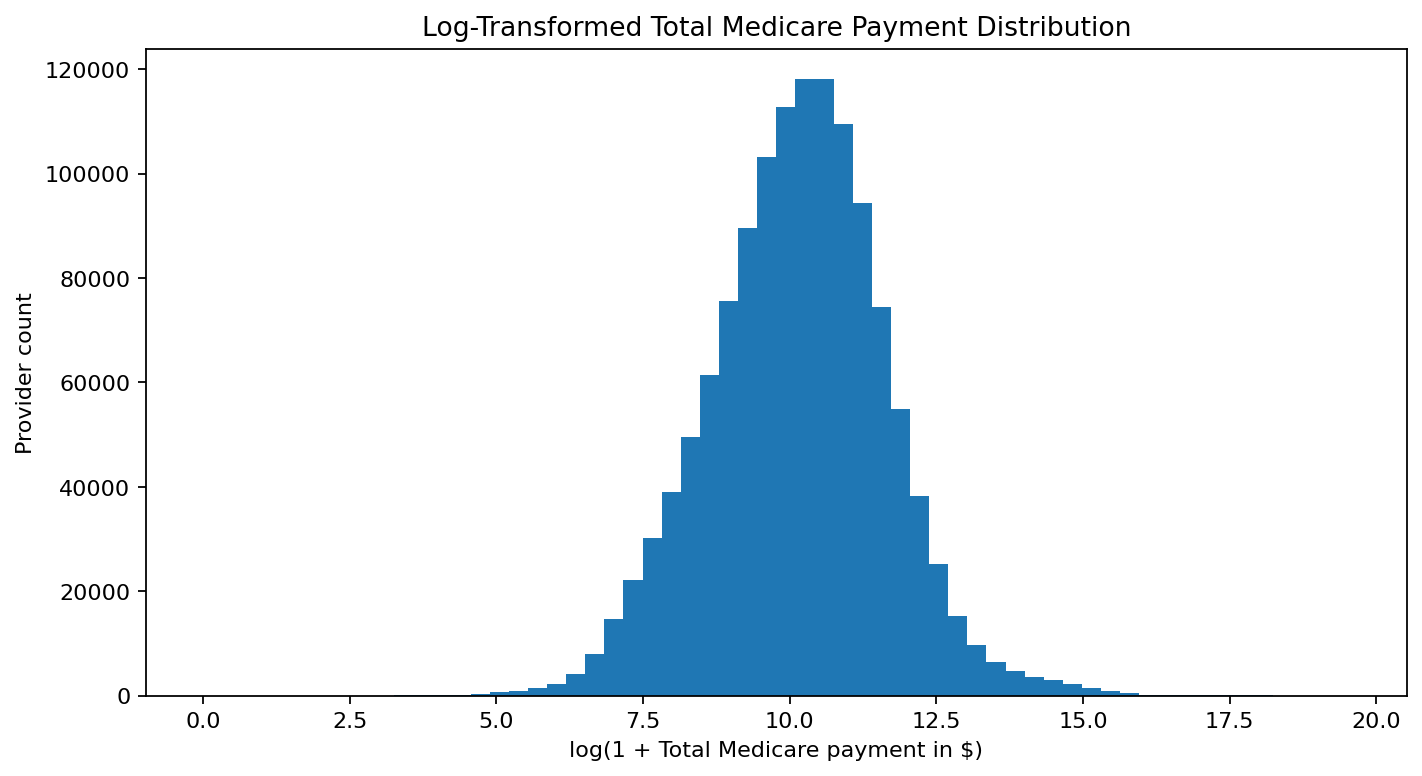

In [17]:
from IPython.display import Image, display

figure_path = (
    project_dir
    / "outputs"
    / "eda"
    / "payment_distribution_log1p.png"
)

display(Image(filename=str(figure_path)))

### To display all available EDA images:

median_payment_top_provider_types.png


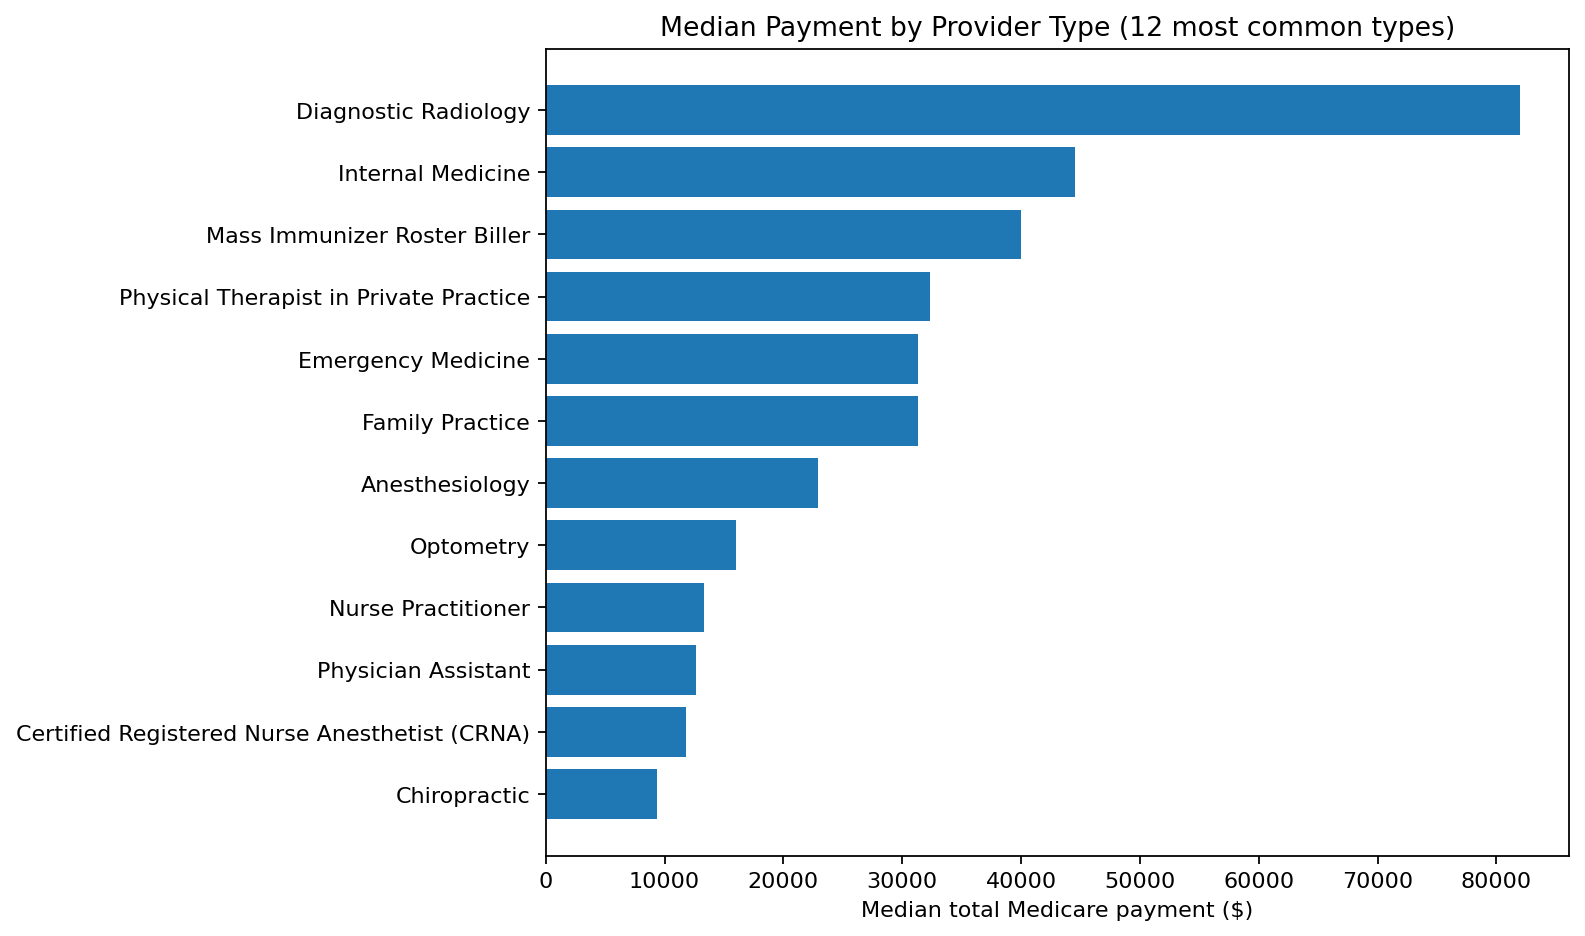

missingness_top25.png


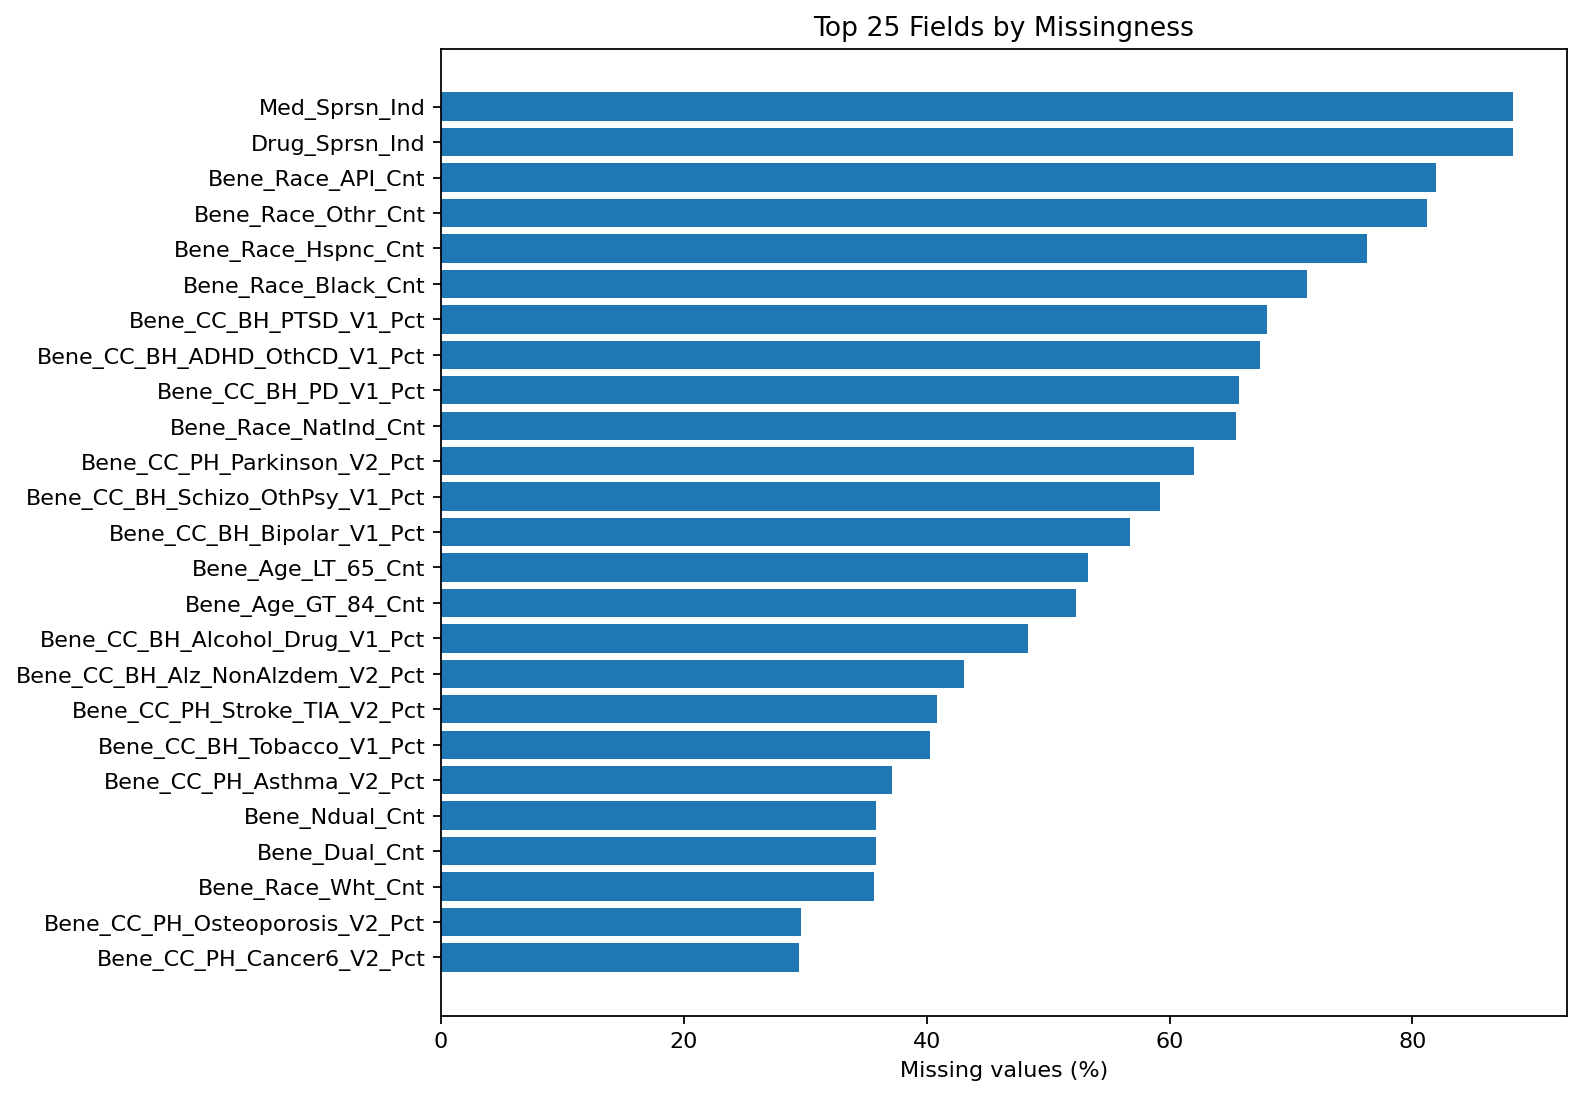

payment_distribution_capped_p99.png


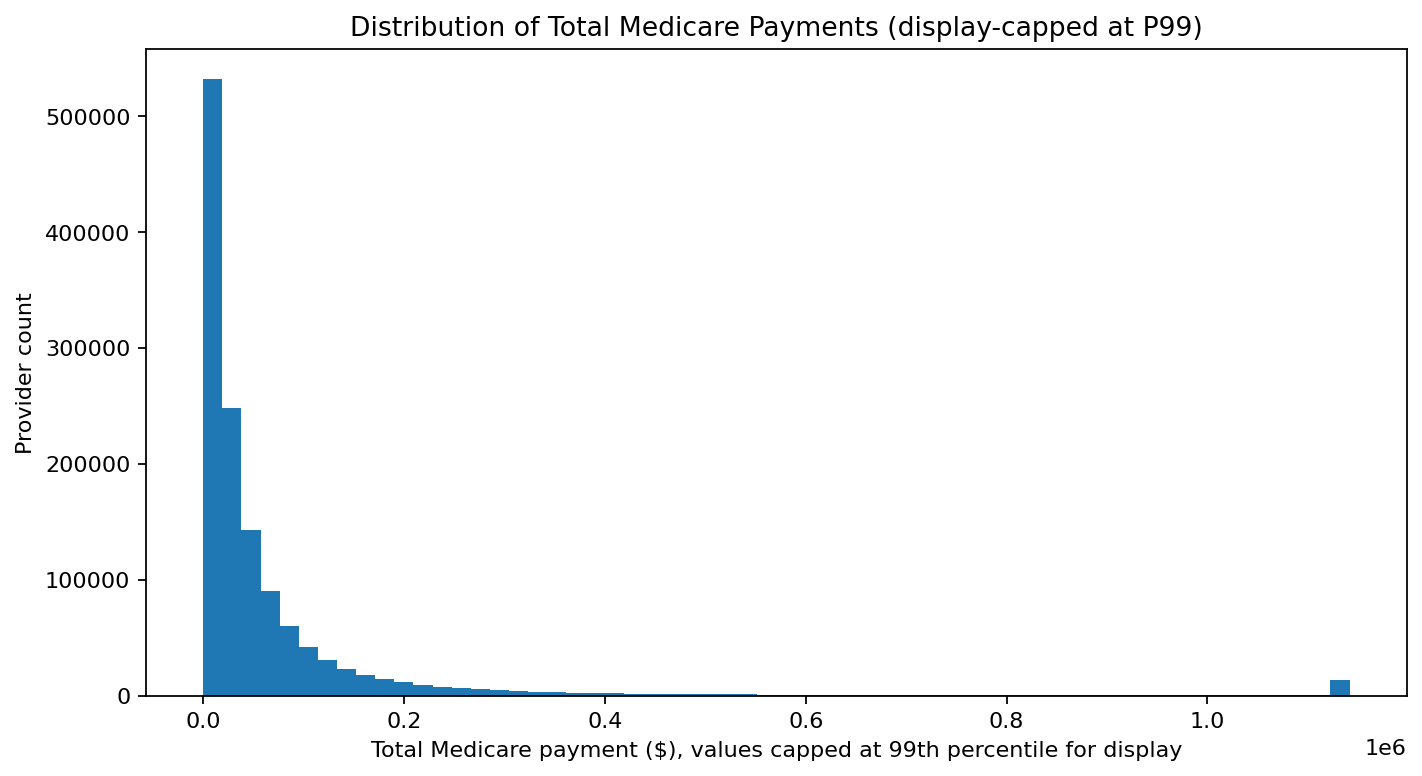

payment_distribution_log1p.png


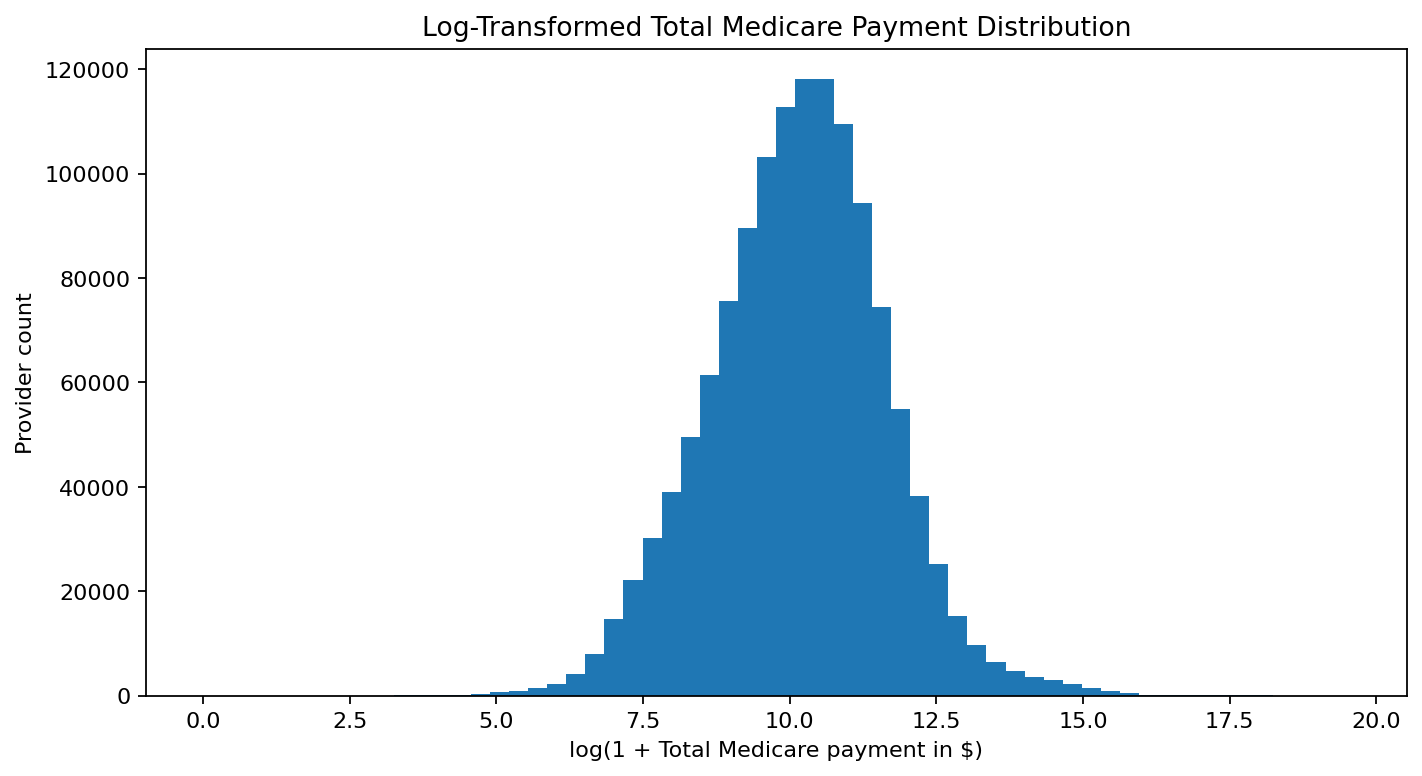

In [18]:
for image_path in sorted(
    (project_dir / "outputs" / "eda").glob("*.png")
):
    print(image_path.name)
    display(Image(filename=str(image_path)))